### shapely 1: Geometrien erstellen, messen und zeichnen - Übungen

**shapely** ist ein Python-Paket für **ebene Geometrie**: Punkte, Strecken, Vielecke. Es berechnet Längen, Flächen und Abstände,
prüft, ob sich Figuren schneiden, und konstruiert neue Figuren. Das Paket wird in Geoinformationssystemen (Landkarten) benutzt,
eignet sich aber auch sehr gut, um Schulgeometrie am Computer nachzurechnen.

Die Reihe hat vier Notebooks:

1. **Grundlagen**: Geometrien erstellen, messen und zeichnen (dieses Notebook)
2. Lagebeziehungen: Lage, Schnittpunkte, Abstände
3. Mengen und Konstruktionen: Schnitt und Vereinigung, Abstandsbereiche, Hüllen, Voronoi-Diagramme
4. Abbildungen und Anwendungen: Verschieben, Drehen, Spiegeln, Strecken; Flächen unter Graphen; Monte-Carlo

Du solltest die Notebooks zu matplotlib (Grundlagen) schon kennen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Punkte

#### `Point`

Ein Punkt wird mit `Point(x, y)` erzeugt. Die Koordinaten erhält man mit `p.x` und `p.y`.
`print(p)` zeigt den Punkt in der **WKT-Schreibweise** (*Well-Known Text*), die alle Geoinformationssysteme verstehen: `POINT (3 4)`.

`p.distance(q)` ist der Abstand zweier Punkte (nach Pythagoras).

In [ ]:
from shapely import Point

p = Point(3, 4)
q = Point(0, 0)
print(p)
print(p.x, p.y)
print(p.distance(q))

#### Gerundet ausgeben

Bei Rechnungen entstehen oft Zahlen wie `2.4999999999999996`. Zum Ausgeben rundet man mit
`shapely.to_wkt(geometrie, rounding_precision=2)` auf 2 Nachkommastellen (überflüssige Nullen fallen weg). Einzelne Zahlen rundet man mit `round()`.
In diesem Notebook werden Ergebnisse immer gerundet ausgegeben.

In [ ]:
import shapely
from shapely import Point

p = Point(1 / 3, 2.5)
print(p)
print(shapely.to_wkt(p, rounding_precision=2))
print(round(Point(0, 0).distance(Point(1, 1)), 3))

#### Aufgabe 1.1

Erzeuge den Punkt A(2|−1) und gib ihn aus, dann seine x- und seine y-Koordinate.

**Erwartete Ausgabe:**
```
POINT (2 -1)
2.0 -1.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

a = Point(2, -1)
print(a)
print(a.x, a.y)
```

</details>

#### Aufgabe 1.2

Gib den Abstand der Punkte A(1|2) und B(7|10) aus.

**Erwartete Ausgabe:**
```
10.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

print(Point(1, 2).distance(Point(7, 10)))
```

</details>

#### Aufgabe 1.3

Gib den Abstand der Punkte A(−2|3) und B(4|−1) auf 3 Nachkommastellen gerundet aus.

**Erwartete Ausgabe:**
```
7.211
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

print(round(Point(-2, 3).distance(Point(4, -1)), 3))
```

</details>

#### Aufgabe 1.4

Berechne den Abstand von A(1|1) und B(4|5) einmal mit `distance()` und einmal selbst mit dem Satz des Pythagoras (Wurzel mit `** 0.5`). Gib beide Werte aus.

**Erwartete Ausgabe:**
```
5.0
5.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

a = Point(1, 1)
b = Point(4, 5)
print(a.distance(b))
print(((b.x - a.x) ** 2 + (b.y - a.y) ** 2) ** 0.5)
```

</details>

#### Aufgabe 1.5

Der Mittelpunkt M einer Strecke AB hat die Koordinaten ((x₁+x₂)/2 | (y₁+y₂)/2). Erzeuge M für A(1|5) und B(4|−2) und gib ihn mit `to_wkt` gerundet auf 2 Stellen aus.
Gib außerdem aus, ob M von A und B gleich weit entfernt ist.

**Erwartete Ausgabe:**
```
POINT (2.5 1.5)
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point

a = Point(1, 5)
b = Point(4, -2)
m = Point((a.x + b.x) / 2, (a.y + b.y) / 2)
print(shapely.to_wkt(m, rounding_precision=2))
print(a.distance(m) == b.distance(m))
```

</details>

#### Aufgabe 1.6

Welcher der Orte in `orte` liegt am nächsten an der Schule S(3|2)? Gib den Namen und den Abstand (2 Nachkommastellen) aus.

**Erwartete Ausgabe:**
```
Linde 2.83
```

In [ ]:
from shapely import Point

schule = Point(3, 2)
orte = {'Ahorn': Point(0, 0), 'Birke': Point(5, 5), 'Eiche': Point(4, -1), 'Linde': Point(1, 4)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

schule = Point(3, 2)
orte = {'Ahorn': Point(0, 0), 'Birke': Point(5, 5), 'Eiche': Point(4, -1), 'Linde': Point(1, 4)}
name = min(orte, key=lambda n: schule.distance(orte[n]))
print(name, round(schule.distance(orte[name]), 2))
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Point

p = Point(0, 0)
q = Point(5, 12)
print(p.distance(q), q.distance(p))
print(Point(2, 2).distance(Point(2, 2)))
```

In [ ]:
from shapely import Point

p = Point(0, 0)
q = Point(5, 12)
print(p.distance(q), q.distance(p))
print(Point(2, 2).distance(Point(2, 2)))

## 2. Strecken und Streckenzüge

#### `LineString`

`LineString([(x1, y1), (x2, y2), ...])` ist ein **Streckenzug** durch die angegebenen Punkte; mit zwei Punkten eine Strecke.

- `l.length` ist die Gesamtlänge.
- `list(l.coords)` gibt die Punkte als Liste von Tupeln zurück.
- `l.bounds` ist das Tupel `(xmin, ymin, xmax, ymax)`: das kleinste achsenparallele Rechteck um die Figur.

In [ ]:
from shapely import LineString

s = LineString([(0, 0), (3, 4)])
weg = LineString([(0, 0), (3, 4), (3, 10), (-2, 10)])
print(s, s.length)
print(weg.length)
print(list(weg.coords))
print(weg.bounds)

#### Aufgabe 2.1

Erzeuge die Strecke von A(1|1) nach B(7|9) und gib ihre Länge aus.

**Erwartete Ausgabe:**
```
10.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

print(LineString([(1, 1), (7, 9)]).length)
```

</details>

#### Aufgabe 2.2

Ein Wanderweg führt über die Punkte (0|0), (4|3), (4|8) und (10|16). Gib seine Länge aus.

**Erwartete Ausgabe:**
```
20.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

weg = LineString([(0, 0), (4, 3), (4, 8), (10, 16)])
print(weg.length)
```

</details>

#### Aufgabe 2.3

Berechne die Länge des Streckenzugs `zug` selbst: Addiere die Längen der Teilstrecken zwischen aufeinanderfolgenden Punkten aus `coords`.
Gib deine Summe (gerundet auf 4 Stellen) und `zug.length` (ebenso gerundet) aus.

**Erwartete Ausgabe:**
```
8.3983
8.3983
```

In [ ]:
from shapely import LineString, Point

zug = LineString([(0, 0), (2, 1), (5, 1), (6, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString, Point

zug = LineString([(0, 0), (2, 1), (5, 1), (6, 4)])
punkte = list(zug.coords)
summe = 0
for i in range(len(punkte) - 1):
    summe += Point(punkte[i]).distance(Point(punkte[i + 1]))
print(round(summe, 4))
print(round(zug.length, 4))
```

</details>

`Point(tupel)` erzeugt einen Punkt auch aus einem Tupel `(x, y)`, so wie es in `coords` steht.

In [ ]:
from shapely import Point

print(Point((2, 5)))

#### Aufgabe 2.4

Gib die `bounds` des Streckenzugs `zug` aus und berechne daraus Breite und Höhe des umgebenden Rechtecks.

**Erwartete Ausgabe:**
```
(-1.0, -1.0, 7.0, 6.0)
8.0 7.0
```

In [ ]:
from shapely import LineString

zug = LineString([(2, 3), (7, -1), (5, 6), (-1, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

zug = LineString([(2, 3), (7, -1), (5, 6), (-1, 2)])
xmin, ymin, xmax, ymax = zug.bounds
print(zug.bounds)
print(xmax - xmin, ymax - ymin)
```

</details>

#### Aufgabe 2.5

Ein Läufer läuft eine Runde über die Punkte in `runde` (am Ende wieder zum Start). Gib die Länge einer Runde aus und wie viele **ganze** Runden er für 10 km
braucht (Koordinaten in Metern, mit `//` und aufrunden: `-(-10000 // laenge)`).

**Erwartete Ausgabe:**
```
320.0
32
```

In [ ]:
from shapely import LineString

runde = LineString([(0, 0), (100, 0), (100, 60), (0, 60), (0, 0)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

runde = LineString([(0, 0), (100, 0), (100, 60), (0, 60), (0, 0)])
laenge = runde.length
print(laenge)
print(int(-(-10000 // laenge)))
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import LineString

l = LineString([(0, 0), (0, 3), (4, 3)])
print(l.length)
print(len(l.coords))
print(l.bounds)
```

In [ ]:
from shapely import LineString

l = LineString([(0, 0), (0, 3), (4, 3)])
print(l.length)
print(len(l.coords))
print(l.bounds)

## 3. Vielecke (Polygone)

#### `Polygon`

`Polygon([(x1, y1), (x2, y2), ...])` ist ein **Vieleck** mit diesen Eckpunkten. Den ersten Punkt muss man am Ende nicht wiederholen, shapely schließt das Vieleck selbst.

| Attribut | bedeutet |
|---|---|
| `area` | Flächeninhalt |
| `length` | Umfang |
| `centroid` | Schwerpunkt (ein `Point`) |
| `bounds` | umgebendes Rechteck |
| `exterior.coords` | die Eckpunkte des Randes (der erste am Ende noch einmal) |

In [ ]:
import shapely
from shapely import Polygon

dreieck = Polygon([(0, 0), (4, 0), (0, 3)])
print(dreieck)
print(dreieck.area, dreieck.length)
print(shapely.to_wkt(dreieck.centroid, rounding_precision=2))
print(list(dreieck.exterior.coords))

#### Vielecke mit Loch

Ein Vieleck kann **Löcher** haben: `Polygon(rand, [loch1, loch2, ...])`. Die Fläche der Löcher wird abgezogen, ihr Rand zählt zum Umfang dazu.
Die Löcher stehen in `interiors`.

In [ ]:
from shapely import Polygon

rahmen = Polygon([(0, 0), (10, 0), (10, 8), (0, 8)], [[(2, 2), (8, 2), (8, 6), (2, 6)]])
print(rahmen.area)
print(rahmen.length)
print(len(rahmen.interiors))

#### Aufgabe 3.1

Erzeuge das Rechteck mit den Ecken (0|0), (6|0), (6|4), (0|4) und gib Fläche und Umfang aus.

**Erwartete Ausgabe:**
```
24.0 20.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

r = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
print(r.area, r.length)
```

</details>

#### Aufgabe 3.2

Gib Fläche und Umfang (2 Nachkommastellen) des Dreiecks A(1|1), B(7|2), C(3|6) aus.

**Erwartete Ausgabe:**
```
14.0
17.12
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

d = Polygon([(1, 1), (7, 2), (3, 6)])
print(d.area)
print(round(d.length, 2))
```

</details>

#### Aufgabe 3.3

Prüfe die Formel für die Trapezfläche A = (a + c) / 2 · h am Trapez mit den Ecken (0|0), (8|0), (6|3), (2|3): Gib die Fläche mit shapely und mit der Formel aus.

**Erwartete Ausgabe:**
```
18.0
18.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

trapez = Polygon([(0, 0), (8, 0), (6, 3), (2, 3)])
a = 8
c = 4
h = 3
print(trapez.area)
print((a + c) / 2 * h)
```

</details>

#### Aufgabe 3.4

Der Schwerpunkt eines Dreiecks ist der Mittelwert der drei Eckpunkte. Gib den `centroid` des Dreiecks A(0|0), B(6|0), C(3|9) gerundet aus und vergleiche mit dem selbst berechneten Mittelwert.

**Erwartete Ausgabe:**
```
POINT (3 3)
3.0 3.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon

d = Polygon([(0, 0), (6, 0), (3, 9)])
print(shapely.to_wkt(d.centroid, rounding_precision=2))
print((0 + 6 + 3) / 3, (0 + 0 + 9) / 3)
```

</details>

#### Aufgabe 3.5

Ein rechteckiger Garten (20 m × 12 m) hat ein rechteckiges Beet von (5|3) bis (11|7), auf dem kein Rasen wächst. Erzeuge den Rasen als Vieleck mit Loch und gib die Rasenfläche
und die Länge aller Ränder zusammen aus.

**Erwartete Ausgabe:**
```
216.0
84.0
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

rasen = Polygon([(0, 0), (20, 0), (20, 12), (0, 12)], [[(5, 3), (11, 3), (11, 7), (5, 7)]])
print(rasen.area)
print(rasen.length)
```

</details>

#### Aufgabe 3.6

Gib für jedes Vieleck in `figuren` den Namen und die Fläche aus, sortiert nach der Fläche (die größte zuerst).

**Erwartete Ausgabe:**
```
Fünfeck 21.0
Dreieck 10.0
Quadrat 9.0
Raute 8.0
```

In [ ]:
from shapely import Polygon

figuren = {'Quadrat': Polygon([(0, 0), (3, 0), (3, 3), (0, 3)]), 'Dreieck': Polygon([(0, 0), (5, 0), (0, 4)]),
           'Raute': Polygon([(0, 2), (2, 0), (4, 2), (2, 4)]), 'Fünfeck': Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

figuren = {'Quadrat': Polygon([(0, 0), (3, 0), (3, 3), (0, 3)]), 'Dreieck': Polygon([(0, 0), (5, 0), (0, 4)]),
           'Raute': Polygon([(0, 2), (2, 0), (4, 2), (2, 4)]), 'Fünfeck': Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])}
for name in sorted(figuren, key=lambda n: figuren[n].area, reverse=True):
    print(name, figuren[name].area)
```

</details>

#### Aufgabe 3.7

Gib aus, wie viele Eckpunkte das Vieleck `p` hat. (In `exterior.coords` steht der erste Punkt am Ende noch einmal.)

**Erwartete Ausgabe:**
```
5
```

In [ ]:
from shapely import Polygon

p = Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

p = Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])
print(len(p.exterior.coords) - 1)
```

</details>

#### Aufgabe 3.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Polygon

q = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
print(q.area, q.length)
print(q.bounds)
print(q.centroid)
```

In [ ]:
from shapely import Polygon

q = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
print(q.area, q.length)
print(q.bounds)
print(q.centroid)

## 4. Zeichnen

#### `shapely.plotting`

Das Modul `shapely.plotting` zeichnet Geometrien mit matplotlib:

| Funktion | zeichnet |
|---|---|
| `plot_points(p, ax=ax, color='red')` | Punkte |
| `plot_line(l, ax=ax, color='C0')` | Strecken und Streckenzüge |
| `plot_polygon(v, ax=ax, facecolor='lightblue', edgecolor='C0')` | Vielecke |

Bei Linien und Vielecken werden die Eckpunkte mitgezeichnet; mit `add_points=False` nicht. `ax.set_aspect('equal')` sorgt dafür,
dass ein Quadrat auch quadratisch aussieht.

In [ ]:
import matplotlib.pyplot as plt
from shapely import Point, LineString, Polygon
from shapely.plotting import plot_points, plot_line, plot_polygon

fig, ax = plt.subplots(figsize=(4, 3))
plot_polygon(Polygon([(0, 0), (4, 0), (4, 3), (0, 3)]), ax=ax, facecolor='lightblue', edgecolor='C0')
plot_line(LineString([(0, 0), (4, 3)]), ax=ax, color='C1')
plot_points(Point(2, 1.5), ax=ax, color='red')
ax.set_aspect('equal')
plt.show()

#### Aufgabe 4.1

Zeichne das Dreieck A(0|0), B(6|0), C(2|4) mit hellgrüner Füllung (`'lightgreen'`) und grünem Rand (`'green'`) und seinen Schwerpunkt als roten Punkt.
Achsen gleich skaliert, Bildgröße 4 × 3.

**Erwartete Ausgabe:**

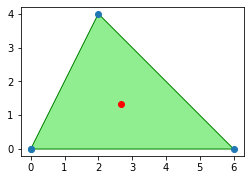

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Polygon
from shapely.plotting import plot_points, plot_polygon

d = Polygon([(0, 0), (6, 0), (2, 4)])
fig, ax = plt.subplots(figsize=(4, 3))
plot_polygon(d, ax=ax, facecolor='lightgreen', edgecolor='green')
plot_points(d.centroid, ax=ax, color='red')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 4.2

Zeichne den Wanderweg über (0|0), (4|3), (4|8), (10|8) ohne Eckpunkte (`add_points=False`) in der Farbe `'C2'` und markiere Start und Ziel als schwarze Punkte.
Setze als Titel die Länge des Weges (z. B. `Länge: 16.0`). Achsen gleich skaliert, Bildgröße 4 × 3.

**Erwartete Ausgabe:**

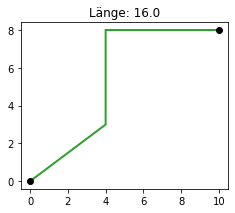

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Point, LineString
from shapely.plotting import plot_points, plot_line

weg = LineString([(0, 0), (4, 3), (4, 8), (10, 8)])
fig, ax = plt.subplots(figsize=(4, 3))
plot_line(weg, ax=ax, color='C2', add_points=False)
plot_points(Point(0, 0), ax=ax, color='black')
plot_points(Point(10, 8), ax=ax, color='black')
ax.set_title(f'Länge: {weg.length}')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 4.3

Zeichne den Garten mit Beet aus Abschnitt 3 (Rechteck 20 × 12 mit Loch von (5|3) bis (11|7)) mit der Füllung `'lightgreen'` und dem Rand `'darkgreen'`.
Das Loch bleibt dabei leer. Achsen gleich skaliert, Bildgröße 5 × 3.

**Erwartete Ausgabe:**

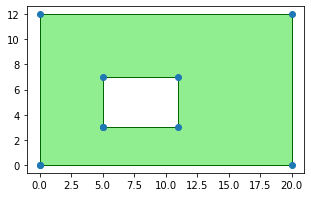

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Polygon
from shapely.plotting import plot_polygon

rasen = Polygon([(0, 0), (20, 0), (20, 12), (0, 12)], [[(5, 3), (11, 3), (11, 7), (5, 7)]])
fig, ax = plt.subplots(figsize=(5, 3))
plot_polygon(rasen, ax=ax, facecolor='lightgreen', edgecolor='darkgreen')
ax.set_aspect('equal')
plt.show()
```

</details>

## 5. Flächenformeln nachrechnen

#### Die Gaußsche Trapezformel

Für ein Vieleck mit den Eckpunkten (x₁|y₁), …, (xₙ|yₙ) gegen den Uhrzeigersinn ist der Flächeninhalt

$$A = \frac{1}{2}\sum_{i=1}^{n} (x_i \cdot y_{i+1} - x_{i+1} \cdot y_i),$$

wobei nach dem letzten Punkt wieder der erste kommt. So rechnet auch shapely. Laufen die Punkte im Uhrzeigersinn, wird die Summe negativ.

In [ ]:
from shapely import Polygon

punkte = [(0, 0), (4, 0), (4, 3), (0, 3)]
s = 0
for i in range(len(punkte)):
    x1, y1 = punkte[i]
    x2, y2 = punkte[(i + 1) % len(punkte)]
    s += x1 * y2 - x2 * y1
print(s / 2, Polygon(punkte).area)

#### Regelmäßige Vielecke

Die Ecken eines regelmäßigen n-Ecks mit Umkreisradius r liegen bei (r·cos(2πk/n) | r·sin(2πk/n)) für k = 0, …, n−1.
Je mehr Ecken, desto näher kommt die Fläche an die Kreisfläche πr².

Auch `Point(x, y).buffer(r)` erzeugt einen „Kreis“, aber eigentlich ist es ein Vieleck mit 64 Ecken (16 pro Viertelkreis, einstellbar mit `quad_segs`).

In [ ]:
import math
from shapely import Point, Polygon

def n_eck(n, r):
    punkte = []
    for k in range(n):
        punkte.append((r * math.cos(2 * math.pi * k / n), r * math.sin(2 * math.pi * k / n)))
    return Polygon(punkte)

for n in [4, 8, 100]:
    print(n, round(n_eck(n, 1).area, 6))
print(round(Point(0, 0).buffer(1).area, 6), len(Point(0, 0).buffer(1).exterior.coords) - 1)
print(round(math.pi, 6))

#### Aufgabe 5.1

Schreibe eine Funktion `flaeche(punkte)` nach der Gaußschen Trapezformel, die bei Punkten im Uhrzeigersinn den Betrag (`abs()`) nimmt. Teste mit den Vielecken in `tests`
und gib jeweils dein Ergebnis und `Polygon(punkte).area` aus.

**Erwartete Ausgabe:**
```
24.0 24.0
14.0 14.0
25.0 25.0
21.0 21.0
```

In [ ]:
from shapely import Polygon

tests = [[(0, 0), (6, 0), (6, 4), (0, 4)], [(1, 1), (7, 2), (3, 6)], [(0, 0), (0, 5), (5, 5), (5, 0)], [(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)]]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

tests = [[(0, 0), (6, 0), (6, 4), (0, 4)], [(1, 1), (7, 2), (3, 6)], [(0, 0), (0, 5), (5, 5), (5, 0)], [(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)]]
def flaeche(punkte):
    s = 0
    for i in range(len(punkte)):
        x1, y1 = punkte[i]
        x2, y2 = punkte[(i + 1) % len(punkte)]
        s += x1 * y2 - x2 * y1
    return abs(s) / 2

for punkte in tests:
    print(flaeche(punkte), Polygon(punkte).area)
```

</details>

#### Aufgabe 5.2

Prüfe die Heronsche Formel A = √(s(s−a)(s−b)(s−c)) mit s = (a+b+c)/2 am Dreieck A(0|0), B(7|0), C(2|5). Berechne die Seitenlängen mit `distance()`.
Gib das Ergebnis der Formel und `area` gerundet auf 6 Stellen aus.

**Erwartete Ausgabe:**
```
17.5
17.5
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

A = Point(0, 0)
B = Point(7, 0)
C = Point(2, 5)
a = B.distance(C)
b = A.distance(C)
c = A.distance(B)
s = (a + b + c) / 2
print(round((s * (s - a) * (s - b) * (s - c)) ** 0.5, 6))
print(round(Polygon([(0, 0), (7, 0), (2, 5)]).area, 6))
```

</details>

#### Aufgabe 5.3

Erzeuge mit der Funktion `n_eck()` aus dem Beispiel regelmäßige n-Ecke mit Radius 1 für n = 6, 12, 24, 48, 96 und gib jeweils n, die Fläche und den Unterschied zu π
(beides auf 6 Stellen gerundet) aus. (So hat schon Archimedes π angenähert.)

**Erwartete Ausgabe:**
```
6 2.598076 0.543516
12 3.0 0.141593
24 3.105829 0.035764
48 3.132629 0.008964
96 3.13935 0.002242
```

In [ ]:
import math
from shapely import Polygon

def n_eck(n, r):
    punkte = []
    for k in range(n):
        punkte.append((r * math.cos(2 * math.pi * k / n), r * math.sin(2 * math.pi * k / n)))
    return Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from shapely import Polygon

def n_eck(n, r):
    punkte = []
    for k in range(n):
        punkte.append((r * math.cos(2 * math.pi * k / n), r * math.sin(2 * math.pi * k / n)))
    return Polygon(punkte)
for n in [6, 12, 24, 48, 96]:
    a = n_eck(n, 1).area
    print(n, round(a, 6), round(math.pi - a, 6))
```

</details>

#### Aufgabe 5.4

Ein regelmäßiges Sechseck mit Radius r hat die Fläche 3√3/2 · r². Prüfe das für r = 2: Gib die Fläche von `n_eck(6, 2)` und den Wert der Formel aus (6 Stellen).

**Erwartete Ausgabe:**
```
10.392305
10.392305
```

In [ ]:
import math
from shapely import Polygon

def n_eck(n, r):
    punkte = []
    for k in range(n):
        punkte.append((r * math.cos(2 * math.pi * k / n), r * math.sin(2 * math.pi * k / n)))
    return Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from shapely import Polygon

def n_eck(n, r):
    punkte = []
    for k in range(n):
        punkte.append((r * math.cos(2 * math.pi * k / n), r * math.sin(2 * math.pi * k / n)))
    return Polygon(punkte)
print(round(n_eck(6, 2).area, 6))
print(round(3 * math.sqrt(3) / 2 * 2 ** 2, 6))
```

</details>

#### Aufgabe 5.5

Erzeuge Kreise um (0|0) mit Radius 1 mit `buffer(1, quad_segs=q)` für q = 1, 2, 4, 16, 64. Gib jeweils q, die Zahl der Ecken und den Fehler zu π (6 Stellen) aus.

**Erwartete Ausgabe:**
```
1 4 1.141593
2 8 0.313166
4 16 0.080125
16 64 0.005044
64 256 0.000315
```

In [ ]:
import math
from shapely import Point
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from shapely import Point
for q in [1, 2, 4, 16, 64]:
    kreis = Point(0, 0).buffer(1, quad_segs=q)
    print(q, len(kreis.exterior.coords) - 1, round(math.pi - kreis.area, 6))
```

</details>

#### Aufgabe 5.6

Für Vielecke mit Ecken auf ganzzahligen Koordinaten gilt der **Satz von Pick**: A = I + R/2 − 1, wobei I die Zahl der Gitterpunkte im Inneren und R die Zahl der Gitterpunkte
auf dem Rand ist. Für das Vieleck `p` sind I = 11 und R = 14. Gib die Fläche nach Pick und mit shapely aus.

**Erwartete Ausgabe:**
```
17.0
17.0
```

In [ ]:
from shapely import Polygon

p = Polygon([(0, 0), (5, 0), (5, 2), (2, 4), (0, 4)])
I = 11
R = 14
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

p = Polygon([(0, 0), (5, 0), (5, 2), (2, 4), (0, 4)])
I = 11
R = 14
print(I + R / 2 - 1)
print(p.area)
```

</details>

## 6. Mehrteilige Geometrien

#### `MultiPoint`, `MultiLineString`, `MultiPolygon`

Mehrere Punkte, Linien oder Vielecke kann man zu **einer** Geometrie zusammenfassen: `MultiPoint([(0, 0), (2, 1)])`,
`MultiPolygon([vieleck1, vieleck2])`. `area` und `length` sind dann die Summen, `centroid` ist der gemeinsame Schwerpunkt.
Die Einzelteile stehen in `geoms`: `len(m.geoms)`, `for g in m.geoms:`.

In [ ]:
import shapely
from shapely import MultiPoint, MultiPolygon, Polygon

punkte = MultiPoint([(0, 0), (4, 0), (2, 5)])
print(len(punkte.geoms))
print(shapely.to_wkt(punkte.centroid, rounding_precision=2))
inseln = MultiPolygon([Polygon([(0, 0), (2, 0), (2, 2), (0, 2)]), Polygon([(5, 5), (8, 5), (8, 6), (5, 6)])])
print(inseln.area)
for insel in inseln.geoms:
    print(insel.area)

#### Aufgabe 6.1

Fasse die Messstationen in `stationen` zu einem `MultiPoint` zusammen. Gib die Anzahl, den Schwerpunkt (gerundet auf 2 Stellen) und die `bounds` aus.

**Erwartete Ausgabe:**
```
5
POINT (5 3.8)
(1.0, 1.0, 9.0, 7.0)
```

In [ ]:
import shapely
from shapely import MultiPoint

stationen = [(1, 2), (4, 7), (6, 1), (9, 4), (5, 5)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint

stationen = [(1, 2), (4, 7), (6, 1), (9, 4), (5, 5)]
m = MultiPoint(stationen)
print(len(m.geoms))
print(shapely.to_wkt(m.centroid, rounding_precision=2))
print(m.bounds)
```

</details>

#### Aufgabe 6.2

Ein Bauer hat drei Felder (`felder`). Fasse sie zu einem `MultiPolygon` zusammen und gib die Gesamtfläche, den Gesamtumfang und die Fläche des größten Feldes aus.

**Erwartete Ausgabe:**
```
2050.0
332.43
1000.0
```

In [ ]:
from shapely import Polygon, MultiPolygon

felder = [Polygon([(0, 0), (40, 0), (40, 25), (0, 25)]), Polygon([(50, 0), (80, 0), (80, 30)]), Polygon([(0, 30), (30, 30), (30, 50), (0, 50)])]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon, MultiPolygon

felder = [Polygon([(0, 0), (40, 0), (40, 25), (0, 25)]), Polygon([(50, 0), (80, 0), (80, 30)]), Polygon([(0, 30), (30, 30), (30, 50), (0, 50)])]
m = MultiPolygon(felder)
print(m.area)
print(round(m.length, 2))
print(max(m.geoms, key=lambda f: f.area).area)
```

</details>

#### Aufgabe 6.3

Gib für jeden Teil des `MultiLineString` `netz` die Länge aus und danach die Gesamtlänge.

**Erwartete Ausgabe:**
```
5.0
6.0
10.0
21.0
```

In [ ]:
from shapely import MultiLineString

netz = MultiLineString([[(0, 0), (3, 4)], [(3, 4), (3, 10)], [(3, 4), (11, 10)]])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import MultiLineString

netz = MultiLineString([[(0, 0), (3, 4)], [(3, 4), (3, 10)], [(3, 4), (11, 10)]])
for linie in netz.geoms:
    print(linie.length)
print(netz.length)
```

</details>

#### Aufgabe 6.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import MultiPoint

m = MultiPoint([(0, 0), (2, 0), (2, 2), (0, 2)])
print(len(m.geoms))
print(m.centroid)
print(m.area, m.length)
```

In [ ]:
from shapely import MultiPoint

m = MultiPoint([(0, 0), (2, 0), (2, 2), (0, 2)])
print(len(m.geoms))
print(m.centroid)
print(m.area, m.length)

## 7. Gemischte Übungen

#### Aufgabe 7.1

Ein Grundstück hat die Eckpunkte in `grundstueck` (Meter). Der Quadratmeter kostet 320 €. Gib die Fläche, den Preis und die Länge des Zauns (Umfang) gerundet auf
2 Stellen aus.

**Erwartete Ausgabe:**
```
638.0
204160.0
98.66
```

In [ ]:
from shapely import Polygon

grundstueck = [(0, 0), (28, 0), (31, 19), (12, 24), (-2, 15)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

grundstueck = [(0, 0), (28, 0), (31, 19), (12, 24), (-2, 15)]
g = Polygon(grundstueck)
print(g.area)
print(g.area * 320)
print(round(g.length, 2))
```

</details>

#### Aufgabe 7.2

Schreibe eine Funktion `ist_rechtwinklig(a, b, c)`, die für drei Punkte prüft, ob das Dreieck rechtwinklig ist (Satz des Pythagoras mit den gerundeten Quadraten der Seitenlängen,
`round(..., 9)`). Teste mit den Dreiecken in `tests`.

**Erwartete Ausgabe:**
```
True
False
False
True
```

In [ ]:
from shapely import Point

tests = [((0, 0), (4, 0), (0, 3)), ((1, 1), (4, 2), (2, 4)), ((0, 0), (5, 0), (2, 3)), ((2, 1), (5, 5), (-2, 4))]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point

tests = [((0, 0), (4, 0), (0, 3)), ((1, 1), (4, 2), (2, 4)), ((0, 0), (5, 0), (2, 3)), ((2, 1), (5, 5), (-2, 4))]
def ist_rechtwinklig(a, b, c):
    seiten = sorted([Point(a).distance(Point(b)), Point(b).distance(Point(c)), Point(a).distance(Point(c))])
    return round(seiten[0] ** 2 + seiten[1] ** 2, 9) == round(seiten[2] ** 2, 9)

for a, b, c in tests:
    print(ist_rechtwinklig(a, b, c))
```

</details>

#### Aufgabe 7.3

Zeichne das Fünfeck `p` mit `'lightyellow'` gefüllt und `'orange'` umrandet, seinen Schwerpunkt als blauen Punkt und die Strecken vom Schwerpunkt zu allen Ecken in grau
(`'gray'`, ohne Eckpunkte). Titel: die Fläche, z. B. `Fläche: 24.0`. Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

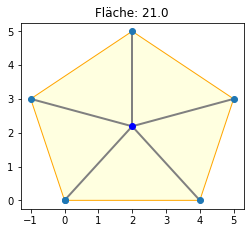

In [ ]:
import matplotlib.pyplot as plt
from shapely import Polygon, LineString
from shapely.plotting import plot_points, plot_line, plot_polygon

p = Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Polygon, LineString
from shapely.plotting import plot_points, plot_line, plot_polygon

p = Polygon([(0, 0), (4, 0), (5, 3), (2, 5), (-1, 3)])
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(p, ax=ax, facecolor='lightyellow', edgecolor='orange')
s = p.centroid
for ecke in list(p.exterior.coords)[:-1]:
    plot_line(LineString([(s.x, s.y), ecke]), ax=ax, color='gray', add_points=False)
plot_points(s, ax=ax, color='blue')
ax.set_title(f'Fläche: {p.area}')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 7.4

Eine Pizza mit Durchmesser 32 cm kostet 9 €, eine mit 26 cm 7 €. Erzeuge beide als `buffer` mit `quad_segs=64` und gib den Preis pro 100 cm² für beide aus (3 Stellen).

**Erwartete Ausgabe:**
```
1.119
1.319
```

In [ ]:
from shapely import Point
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point
gross = Point(0, 0).buffer(16, quad_segs=64)
klein = Point(0, 0).buffer(13, quad_segs=64)
print(round(9 / gross.area * 100, 3))
print(round(7 / klein.area * 100, 3))
```

</details>